**PINN**

Epoch 0: Loss = 48.380123138427734
Epoch 1000: Loss = 0.001243515987880528


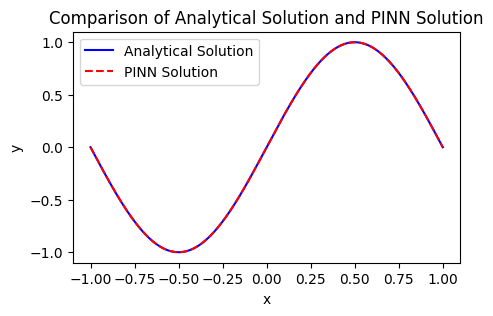

In [ ]:
"""
Physics-Informed Neural Network (PINN) for Poisson's Equation in One Dimension
-----------------------------------------------------------------------------
Equation: d²y/dx² + π² sin(πx) = 0, for x ∈ [-1, 1]
Boundary Conditions: y(-1) = 0, y(1) = 0
Analytical Solution: y(x) = sin(πx)

This code builds, trains, and visualizes a PINN solution step-by-step with clear comments.
"""

# ------------------------- Import required libraries -------------------------
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------- Plot settings for consistency -------------------------
plt.close('all')
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'Times New Roman'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 100

# ------------------------- Define the neural network -------------------------
def create_model():
    """
    This function defines and returns a dictionary-based neural network model.
    Each Dense layer uses the tanh activation function.
    The output layer has no activation (linear output).
    """
    model = {
        'dense1': tf.keras.layers.Dense(50, activation='tanh'),
        'dense2': tf.keras.layers.Dense(50, activation='tanh'),
        'dense3': tf.keras.layers.Dense(50, activation='tanh'),
        'output_layer': tf.keras.layers.Dense(1)
    }
    return model

def call_model(model, x):
    """
    Defines the forward pass through the neural network.
    Takes as input the model (dictionary of layers) and input tensor x.
    """
    x = model['dense1'](x)
    x = model['dense2'](x)
    x = model['dense3'](x)
    x = model['output_layer'](x)
    return x

# ------------------------- Define the PDE residual -------------------------
def pde(x, model):
    """
    Computes the residual of the Poisson equation:
        r(x) = y'' + π² sin(πx)
    using automatic differentiation with tf.GradientTape.
    """
    with tf.GradientTape(persistent=True) as tape:
        tape.watch(x)
        y_pred = call_model(model, x)   # Forward pass: y(x)
        y_x = tape.gradient(y_pred, x)  # First derivative y'(x)
    y_xx = tape.gradient(y_x, x)        # Second derivative y''(x)
    del tape
    return y_xx + np.pi**2 * tf.sin(np.pi * x)

# ------------------------- Define the total loss -------------------------
def loss(model, x, x_bc, y_bc):
    """
    Total loss = PDE residual loss + Boundary condition loss.
    - loss_pde ensures the model satisfies the differential equation.
    - loss_bc ensures it satisfies boundary conditions.
    """
    res = pde(x, model)
    loss_pde = tf.reduce_mean(tf.square(res))

    # Predict values at boundary points
    y_bc_pred = call_model(model, x_bc)
    loss_bc = tf.reduce_mean(tf.square(y_bc - y_bc_pred))

    return loss_pde + loss_bc

# ------------------------- Define the training step -------------------------
def train_step(model, x, x_bc, y_bc, optimizer):
    """
    Performs one training step using TensorFlow’s automatic differentiation.
    Computes loss, its gradients, and updates model weights.
    """
    with tf.GradientTape() as tape:
        loss_value = loss(model, x, x_bc, y_bc)

    # Compute gradients with respect to model variables
    grads = tape.gradient(loss_value, [layer.trainable_variables for layer in model.values()])
    grads = [grad for sublist in grads for grad in sublist]  # Flatten gradients
    variables = [var for layer in model.values() for var in layer.trainable_variables]

    # Apply gradients using optimizer
    optimizer.apply_gradients(zip(grads, variables))

    return loss_value

# ------------------------- Set up training data -------------------------
# Collocation points (interior)
x_train = np.linspace(-1, 1, 100).reshape(-1, 1)
x_train = tf.convert_to_tensor(x_train, dtype=tf.float32)

# Boundary points
x_bc = np.array([[-1.0], [1.0]], dtype=np.float32)
y_bc = np.array([[0.0], [0.0]], dtype=np.float32)
x_bc = tf.convert_to_tensor(x_bc, dtype=tf.float32)
y_bc = tf.convert_to_tensor(y_bc, dtype=tf.float32)

# ------------------------- Initialize model and optimizer -------------------------
model = create_model()

# Use exponential decay learning rate schedule
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=1000,
    decay_rate=0.9)
optimizer = tf.keras.optimizers.Adam(learning_rate=lr_schedule)

# ------------------------- Training loop -------------------------
epochs = 2000
for epoch in range(epochs):
    loss_value = train_step(model, x_train, x_bc, y_bc, optimizer)
    if epoch % 1000 == 0:
        print(f"Epoch {epoch}: Loss = {loss_value.numpy()}")

# ------------------------- Predict and compare with analytical solution -------------------------
x_test = np.linspace(-1, 1, 1000).reshape(-1, 1)
x_test_tf = tf.convert_to_tensor(x_test, dtype=tf.float32)
y_pred = call_model(model, x_test_tf).numpy()
y_true = np.sin(np.pi * x_test)

# ------------------------- Plot results -------------------------
plt.figure(figsize=(5, 3))
plt.plot(x_test, y_true, 'b-', label='Analytical Solution')
plt.plot(x_test, y_pred, 'r--', label='PINN Solution')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('Comparison of Analytical Solution and PINN Solution')
plt.show()


## Including Residual Plot as well

Epoch 0: Loss = 47.5938720703125
Epoch 1000: Loss = 0.0003058002912439406


Relative L2 error: 4.035e-03


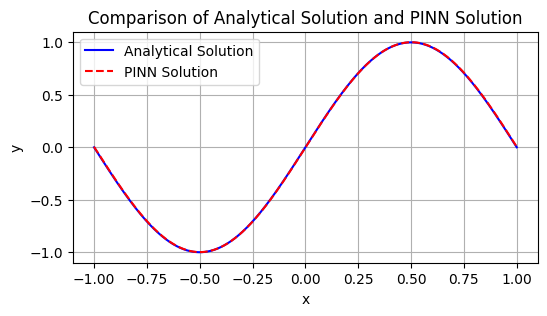

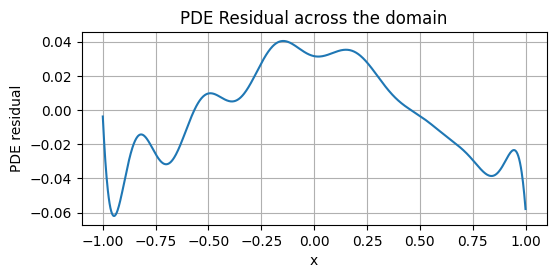

In [ ]:
"""
Physics-Informed Neural Network (PINN) for Poisson's Equation in One Dimension
-----------------------------------------------------------------------------
Equation: d²y/dx² + π² sin(πx) = 0, for x ∈ [-1, 1]
Boundary Conditions: y(-1) = 0, y(1) = 0
Analytical Solution: y(x) = sin(πx)

This code builds, trains, and visualizes a PINN solution step-by-step with clear comments.
"""

# ------------------------- Import required libraries -------------------------
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------- Plot settings for consistency -------------------------
plt.close('all')
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'Times New Roman'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 100

# ------------------------- Define the neural network -------------------------
def create_model():
    """
    This function defines and returns a dictionary-based neural network model.
    Each Dense layer uses the tanh activation function.
    The output layer has no activation (linear output).
    """
    model = {
        'dense1': tf.keras.layers.Dense(50, activation='tanh'),
        'dense2': tf.keras.layers.Dense(50, activation='tanh'),
        'dense3': tf.keras.layers.Dense(50, activation='tanh'),
        'output_layer': tf.keras.layers.Dense(1)
    }
    return model

def call_model(model, x):
    """
    Defines the forward pass through the neural network.
    Takes as input the model (dictionary of layers) and input tensor x.
    """
    x = model['dense1'](x)
    x = model['dense2'](x)
    x = model['dense3'](x)
    x = model['output_layer'](x)
    return x

# ------------------------- Define the PDE residual -------------------------
def pde(x, model):
    """
    Computes the residual of the Poisson equation:
        r(x) = y'' + π² sin(πx)
    using automatic differentiation with tf.GradientTape.
    """
    # Use persistent tape to compute second derivative
    with tf.GradientTape(persistent=True) as tape:
        tape.watch(x)
        y_pred = call_model(model, x)   # Forward pass: y(x)
        y_x = tape.gradient(y_pred, x)  # First derivative y'(x)
    y_xx = tape.gradient(y_x, x)        # Second derivative y''(x)
    del tape
    return y_xx + np.pi**2 * tf.sin(np.pi * x)

# ------------------------- Define the total loss -------------------------
def loss(model, x, x_bc, y_bc):
    """
    Total loss = PDE residual loss + Boundary condition loss.
    - loss_pde ensures the model satisfies the differential equation.
    - loss_bc ensures it satisfies boundary conditions.
    """
    res = pde(x, model)
    loss_pde = tf.reduce_mean(tf.square(res))

    # Predict values at boundary points
    y_bc_pred = call_model(model, x_bc)
    loss_bc = tf.reduce_mean(tf.square(y_bc - y_bc_pred))

    return loss_pde + loss_bc

# ------------------------- Define the training step -------------------------
def train_step(model, x, x_bc, y_bc, optimizer):
    """
    Performs one training step using TensorFlow’s automatic differentiation.
    Computes loss, its gradients, and updates model weights.
    """
    with tf.GradientTape() as tape:
        loss_value = loss(model, x, x_bc, y_bc)

    # Compute gradients with respect to model variables
    grads = tape.gradient(loss_value, [layer.trainable_variables for layer in model.values()])
    grads = [grad for sublist in grads for grad in sublist]  # Flatten gradients
    variables = [var for layer in model.values() for var in layer.trainable_variables]

    # Apply gradients using optimizer
    optimizer.apply_gradients(zip(grads, variables))

    return loss_value

# ------------------------- Set up training data -------------------------
# Collocation points (interior)
x_train = np.linspace(-1, 1, 100).reshape(-1, 1)
x_train = tf.convert_to_tensor(x_train, dtype=tf.float32)

# Boundary points
x_bc = np.array([[-1.0], [1.0]], dtype=np.float32)
y_bc = np.array([[0.0], [0.0]], dtype=np.float32)
x_bc = tf.convert_to_tensor(x_bc, dtype=tf.float32)
y_bc = tf.convert_to_tensor(y_bc, dtype=tf.float32)

# ------------------------- Initialize model and optimizer -------------------------
model = create_model()

# Use exponential decay learning rate schedule
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=1000,
    decay_rate=0.9)
optimizer = tf.keras.optimizers.Adam(learning_rate=lr_schedule)

# ------------------------- Training loop -------------------------
epochs = 2000
for epoch in range(epochs):
    loss_value = train_step(model, x_train, x_bc, y_bc, optimizer)
    if epoch % 1000 == 0:
        print(f"Epoch {epoch}: Loss = {loss_value.numpy()}")

# ------------------------- Predict and compare with analytical solution -------------------------
x_test = np.linspace(-1, 1, 1000).reshape(-1, 1)
x_test_tf = tf.convert_to_tensor(x_test, dtype=tf.float32)
y_pred = call_model(model, x_test_tf).numpy()
y_true = np.sin(np.pi * x_test)

# ------------------------- Compute PDE residual on test grid -------------------------
# Evaluate the PDE residual r(x) = y'' + pi^2 sin(pi x) on the dense test grid to visualize how well the PDE is satisfied
residual_tf = pde(x_test_tf, model)         # tf.Tensor of residuals
residual = residual_tf.numpy().reshape(-1)  # convert to numpy array for plotting

# ------------------------- Compute L2 relative error -------------------------
# Relative L2 error = ||y_true - y_pred||_2 / ||y_true||_2
l2_error = np.linalg.norm(y_true.reshape(-1) - y_pred.reshape(-1), 2) / np.linalg.norm(y_true.reshape(-1), 2)
print(f"Relative L2 error: {l2_error:.3e}")

# ------------------------- Plot results: solution and residual -------------------------
plt.figure(figsize=(6, 3))
plt.plot(x_test, y_true, 'b-', label='Analytical Solution')
plt.plot(x_test, y_pred, 'r--', label='PINN Solution')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title('Comparison of Analytical Solution and PINN Solution')
plt.grid(True)
plt.show()

# Plot PDE residual
plt.figure(figsize=(6, 2.5))
plt.plot(x_test, residual)
plt.xlabel('x')
plt.ylabel('PDE residual')
plt.title('PDE Residual across the domain')
plt.grid(True)
plt.show()


# Diffusion equation plot first for analytic using D=1 n=1 L=1

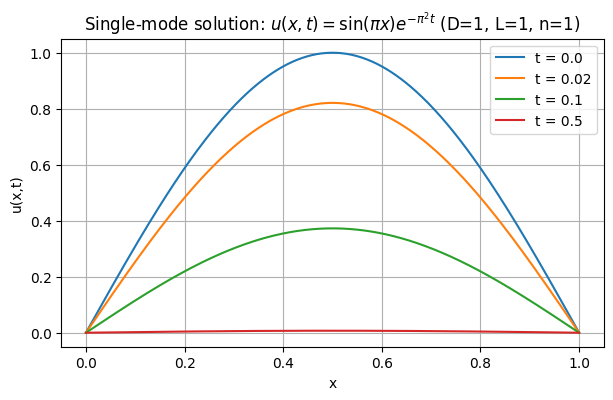

In [ ]:
# Analytical single-mode solution plot for D=1, n=1, L=1
# u(x,t) = sin(pi * x) * exp(-pi^2 * t)

import numpy as np
import matplotlib.pyplot as plt

# Parameters
D = 1.0     # diffusivity (unused in formula since D=1)
L = 1.0     # domain length
n = 1       # single mode index
A1 = 1.0    # amplitude for mode n=1

# spatial grid
x = np.linspace(0, L, 400)

# times to show
times = [0.0, 0.02, 0.1, 0.5]

plt.figure(figsize=(7,4))
for t in times:
    # analytic single-mode formula
    u = A1 * np.sin(np.pi * n * x / L) * np.exp(-D * (np.pi * n / L)**2 * t)
    plt.plot(x, u, label=f"t = {t}")
plt.xlabel("x")
plt.ylabel("u(x,t)")
plt.title(r"Single-mode solution: $u(x,t)=\sin(\pi x)e^{-\pi^2 t}$ (D=1, L=1, n=1)")
plt.legend()
plt.grid(True)
plt.show()


# Calcutaion of exponent term values

In [ ]:
import numpy as np
import pandas as pd

# Times (same as before)
t_values = [0.0, 0.02, 0.1, 0.5]

# Compute π²
pi_sq = np.pi**2

# Prepare lists
pi_sq_list = []
pi_sq_t_list = []
exp_decay_list = []

for t in t_values:
    pi_sq_list.append(pi_sq)
    pi_sq_t = pi_sq * t
    pi_sq_t_list.append(pi_sq_t)
    exp_decay_list.append(np.exp(-pi_sq_t))  # exp(-π²t)

# Create a pandas DataFrame for nice formatting
df = pd.DataFrame({
    "Time (t)": t_values,
    "π²": [round(pi_sq, 6)] * len(t_values),
    "π² × t": [round(val, 6) for val in pi_sq_t_list],
    "exp(-π² × t)": [round(val, 6) for val in exp_decay_list]
})

print("Table of π², π² × t, and exp(-π² × t) values:")
print(df.to_string(index=False))


Table of π², π² × t, and exp(-π² × t) values:
 Time (t)       π²   π² × t  exp(-π² × t)
     0.00 9.869604 0.000000      1.000000
     0.02 9.869604 0.197392      0.820869
     0.10 9.869604 0.986960      0.372708
     0.50 9.869604 4.934802      0.007192


# PINN code for 1D diffusion

Starting training...
Epoch    1 | total=5.537e-01 pde=6.814e-02 ic=4.806e-01 bc=4.985e-03
Epoch  500 | total=6.890e-02 pde=6.814e-02 ic=5.910e-04 bc=1.624e-04
Epoch 1000 | total=6.840e-02 pde=6.814e-02 ic=2.086e-04 bc=5.208e-05
Epoch 1500 | total=6.829e-02 pde=6.814e-02 ic=1.160e-04 bc=3.014e-05
Epoch 2000 | total=6.824e-02 pde=6.814e-02 ic=7.737e-05 bc=1.895e-05
Epoch 2500 | total=6.824e-02 pde=6.814e-02 ic=7.134e-05 bc=2.777e-05
Epoch 3000 | total=6.819e-02 pde=6.814e-02 ic=4.110e-05 bc=1.060e-05
Training finished.


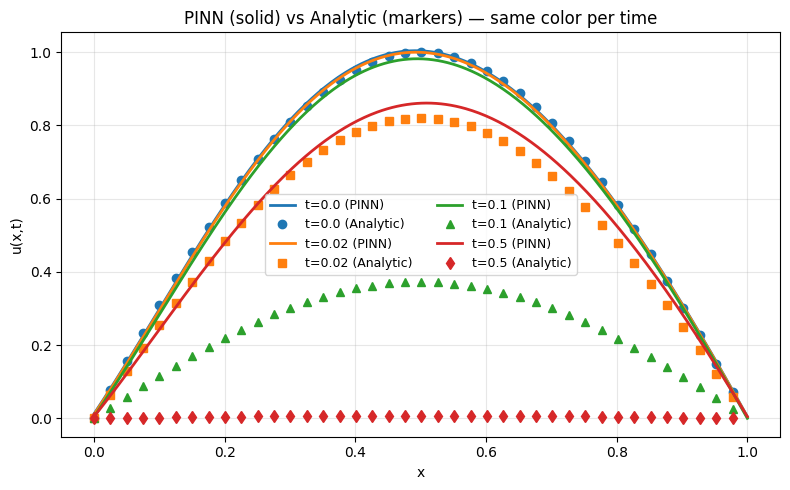

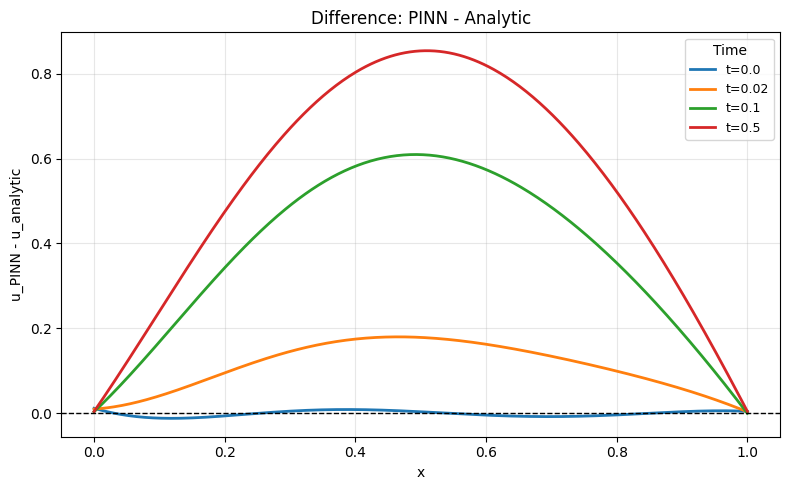


Relative L2 errors (per time):
 t =  0.0  | relative L2 error = 9.061e-03
 t = 0.02  | relative L2 error = 2.127e-01
 t =  0.1  | relative L2 error = 1.619e+00
 t =  0.5  | relative L2 error = 1.184e+02

Max absolute PDE residual on evaluation grid (t=0.02): 10.183772


In [ ]:
"""
Full script (self-contained) that:
1) Trains a PINN for the 1D diffusion (heat) equation with D=1, L=1,
   initial condition u(x,0)=sin(pi x), Dirichlet BC u(0,t)=u(1,t)=0.
2) Plots PINN (solid lines) vs analytic (markers) for times t = [0,0.02,0.1,0.5],
   ensuring same color per time, markers for analytic only.
3) Plots the difference (PINN - analytic) for each time.
4) Prints per-time relative L2 errors.

Requirements:
 - Python 3.8+
 - numpy, matplotlib, tensorflow (tested with TF 2.x)

Run as a single script or paste into a Jupyter cell.
"""

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# -------------------- reproducibility --------------------
np.random.seed(1234)
tf.random.set_seed(1234)

# -------------------- PDE problem parameters --------------------
D = 1.0          # diffusivity
L = 1.0          # spatial domain length [0, L]
T_final = 0.5    # final time used for training/evaluation

# initial condition function f(x) = sin(pi x) (single-mode)
def f_init(x):
    return np.sin(np.pi * x).reshape(-1, 1)

# -------------------- PINN model definition --------------------
class PINN(tf.keras.Model):
    """Simple fully-connected PINN mapping (x,t) -> u(x,t)."""
    def __init__(self, widths=[50,50,50]):
        super().__init__()
        self.hidden = [tf.keras.layers.Dense(w, activation=tf.nn.tanh,
                                             kernel_initializer='glorot_normal')
                       for w in widths]
        self.out = tf.keras.layers.Dense(1, activation=None,
                                         kernel_initializer='glorot_normal')

    @tf.function
    def call(self, xt):
        # xt shape: (batch, 2) with columns [x, t]
        z = xt
        for layer in self.hidden:
            z = layer(z)
        return self.out(z)   # shape (batch, 1)

# -------------------- utility: compute derivatives and PDE residual --------------------
@tf.function
def pde_residual(model, xt):
    """
    Compute PDE residual r = u_t - D*u_xx and also return u, u_t, u_x, u_xx.
    xt: tf.Tensor of shape (N,2) with columns [x, t].
    """
    # split x and t so we can take derivatives w.r.t each
    x = xt[:, 0:1]   # shape (N,1)
    t = xt[:, 1:2]   # shape (N,1)

    # Use gradient tapes to obtain first and second derivatives
    with tf.GradientTape(persistent=True) as tape2:
        tape2.watch([x, t])
        with tf.GradientTape(persistent=True) as tape1:
            tape1.watch([x, t])
            xt_in = tf.concat([x, t], axis=1)
            u = model(xt_in)              # u(x,t)
        u_x = tape1.gradient(u, x)        # du/dx
        u_t = tape1.gradient(u, t)        # du/dt
    u_xx = tape2.gradient(u_x, x)        # d^2u/dx^2

    # free tapes
    del tape1
    del tape2

    # residual r = u_t - D * u_xx
    r = u_t - D * u_xx
    return r, u, u_t, u_x, u_xx

# -------------------- loss function --------------------
@tf.function
def loss_fn(model,
            x_coll_tf, t_coll_tf,
            x_ic_tf, t_ic_tf, u_ic_tf,
            x_b_tf, t_b_tf, u_b_tf):
    """
    Computes total loss = MSE(PDE residual at collocation points) +
                          MSE(initial condition) +
                          MSE(boundary condition)
    """
    # collocation loss (interior points)
    xt_coll = tf.concat([x_coll_tf, t_coll_tf], axis=1)
    r_coll, _, _, _, _ = pde_residual(model, xt_coll)
    loss_pde = tf.reduce_mean(tf.square(r_coll))

    # initial condition loss (t=0)
    xt_ic = tf.concat([x_ic_tf, t_ic_tf], axis=1)
    # we can get u_pred from pde_residual call (it returns u as second output)
    _, u_pred_ic, _, _, _ = pde_residual(model, xt_ic)
    loss_ic = tf.reduce_mean(tf.square(u_pred_ic - u_ic_tf))

    # boundary condition loss (x=0 and x=L)
    xt_b = tf.concat([x_b_tf, t_b_tf], axis=1)
    _, u_pred_b, _, _, _ = pde_residual(model, xt_b)
    loss_bc = tf.reduce_mean(tf.square(u_pred_b - u_b_tf))

    total_loss = loss_pde + loss_ic + loss_bc
    return total_loss, loss_pde, loss_ic, loss_bc

# -------------------- generate training data --------------------
# Collocation points (random inside domain) where PDE residual is enforced
N_coll = 2000
x_coll = np.random.rand(N_coll, 1) * L           # uniform in (0, L)
t_coll = np.random.rand(N_coll, 1) * T_final     # uniform in (0, T_final)

# Initial condition points (t=0)
N_ic = 200
x_ic = np.linspace(0, L, N_ic).reshape(-1,1)
t_ic = np.zeros_like(x_ic)
u_ic = f_init(x_ic)    # shape (N_ic, 1)

# Boundary condition points (x=0 and x=L) at random times
N_bc = 200
t_bc_rand = np.random.rand(N_bc, 1) * T_final
# split into two halves for x=0 and x=L
x_b0 = np.zeros((N_bc//2,1))
x_bL = L * np.ones((N_bc - N_bc//2, 1))
x_b = np.vstack([x_b0, x_bL])
t_b = np.vstack([t_bc_rand[:N_bc//2], t_bc_rand[N_bc//2:]])
u_b = np.zeros_like(t_b)   # Dirichlet BC (zero)

# Convert numpy arrays to tf tensors for training
x_coll_tf = tf.convert_to_tensor(x_coll, dtype=tf.float32)
t_coll_tf = tf.convert_to_tensor(t_coll, dtype=tf.float32)
x_ic_tf = tf.convert_to_tensor(x_ic, dtype=tf.float32)
t_ic_tf = tf.convert_to_tensor(t_ic, dtype=tf.float32)
u_ic_tf = tf.convert_to_tensor(u_ic, dtype=tf.float32)
x_b_tf = tf.convert_to_tensor(x_b, dtype=tf.float32)
t_b_tf = tf.convert_to_tensor(t_b, dtype=tf.float32)
u_b_tf = tf.convert_to_tensor(u_b, dtype=tf.float32)

# -------------------- create model & optimizer --------------------
model = PINN(widths=[50,50,50])
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

# -------------------- training step --------------------
@tf.function
def train_step():
    with tf.GradientTape() as tape:
        total_loss, loss_pde, loss_ic, loss_bc = loss_fn(
            model,
            x_coll_tf, t_coll_tf,
            x_ic_tf, t_ic_tf, u_ic_tf,
            x_b_tf, t_b_tf, u_b_tf
        )
    variables = model.trainable_variables
    grads = tape.gradient(total_loss, variables)
    optimizer.apply_gradients(zip(grads, variables))
    return total_loss, loss_pde, loss_ic, loss_bc

# -------------------- training loop --------------------
epochs = 3000
print_every = 500
print("Starting training...")
for ep in range(1, epochs+1):
    tot, lpde, lic, lbc = train_step()
    if ep % print_every == 0 or ep == 1:
        print(f"Epoch {ep:4d} | total={tot.numpy():.3e} pde={lpde.numpy():.3e} ic={lic.numpy():.3e} bc={lbc.numpy():.3e}")
print("Training finished.")

# -------------------- evaluation grid & plot settings --------------------
# spatial grid for plotting
x_plot = np.linspace(0, L, 400)
# times to visualize (same as you requested)
t_plot = [0.0, 0.02, 0.1, 0.5]

# colors and markers: same color per time, solid for PINN, markers for analytic
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
markers = ['o', 's', '^', 'd']

# -------------------- Plot: PINN (solid) vs Analytic (markers, same color) --------------------
plt.figure(figsize=(8,5))
for i, tval in enumerate(t_plot):
    # build input tensor for model prediction at time tval (all x)
    X = x_plot.reshape(-1,1)
    T = (tval * np.ones_like(X)).reshape(-1,1)
    XT = tf.convert_to_tensor(np.hstack([X, T]), dtype=tf.float32)

    # PINN prediction (solid line)
    u_pred = model(XT).numpy().reshape(-1)
    plt.plot(x_plot, u_pred, color=colors[i], linewidth=2, label=f"t={tval} (PINN)")

    # Analytic solution (markers only, same color)
    u_true = np.sin(np.pi * x_plot) * np.exp(-D * (np.pi**2) * tval)
    # plot only every 10th symbol to make spacing clearer
    plt.plot(x_plot[::10], u_true[::10], linestyle='None',
         marker=markers[i], color=colors[i],
         markersize=6, label=f"t={tval} (Analytic)")


plt.xlabel("x")
plt.ylabel("u(x,t)")
plt.title("PINN (solid) vs Analytic (markers) — same color per time")
plt.legend(ncol=2, fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------- Plot: difference (PINN - Analytic) for each time --------------------
plt.figure(figsize=(8,5))
for i, tval in enumerate(t_plot):
    X = x_plot.reshape(-1,1)
    T = (tval * np.ones_like(X)).reshape(-1,1)
    XT = tf.convert_to_tensor(np.hstack([X, T]), dtype=tf.float32)
    u_pred = model(XT).numpy().reshape(-1)
    u_true = np.sin(np.pi * x_plot) * np.exp(-D * (np.pi**2) * tval)
    diff = u_pred - u_true
    plt.plot(x_plot, diff, color=colors[i], linewidth=2, label=f"t={tval}")

plt.axhline(0.0, color='k', linestyle='--', linewidth=1)
plt.xlabel("x")
plt.ylabel("u_PINN - u_analytic")
plt.title("Difference: PINN - Analytic")
plt.legend(title="Time", fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------- Compute and print relative L2 errors per time --------------------
print("\nRelative L2 errors (per time):")
for i, tval in enumerate(t_plot):
    X = x_plot.reshape(-1,1)
    T = (tval * np.ones_like(X)).reshape(-1,1)
    XT = tf.convert_to_tensor(np.hstack([X, T]), dtype=tf.float32)
    u_pred = model(XT).numpy().reshape(-1)
    u_true = np.sin(np.pi * x_plot) * np.exp(-D * (np.pi**2) * tval)
    # relative L2 error = ||u_pred - u_true||_2 / ||u_true||_2
    num = np.linalg.norm(u_pred - u_true, 2)
    denom = np.linalg.norm(u_true, 2)
    rel_l2 = num / (denom + 1e-16)   # tiny eps to avoid div by zero
    print(f" t = {tval:>4}  | relative L2 error = {rel_l2:.3e}")

# -------------------- optional: print max PDE residual on evaluation grid at t=0.02 --------------------
t_eval = 0.02
XT_eval = tf.convert_to_tensor(np.hstack([x_plot.reshape(-1,1), t_eval*np.ones((len(x_plot),1))]), dtype=tf.float32)
r_eval, u_eval, u_t_eval, u_x_eval, u_xx_eval = pde_residual(model, XT_eval)
res_np = r_eval.numpy().reshape(-1)
print("\nMax absolute PDE residual on evaluation grid (t=0.02):", np.max(np.abs(res_np)))


# PINN improved with LBFGS optimizer and non-uniform sampling, to tackle deviation issue at higher time steps

Adam training start...
Epoch    1 | total=3.634e-01 pde=4.807e-03 ic=2.893e-01 bc=6.931e-02
Epoch  500 | total=9.137e-03 pde=4.224e-03 ic=2.301e-03 bc=2.612e-03
Epoch 1000 | total=1.125e-03 pde=7.985e-04 ic=1.216e-04 bc=2.054e-04
Epoch 1500 | total=4.332e-04 pde=3.421e-04 ic=3.078e-05 bc=6.030e-05
Epoch 2000 | total=6.716e-04 pde=4.663e-04 ic=9.708e-05 bc=1.082e-04
Epoch 2500 | total=1.612e-04 pde=1.236e-04 ic=7.445e-06 bc=3.007e-05
Epoch 3000 | total=1.239e-04 pde=9.439e-05 ic=5.086e-06 bc=2.441e-05
Epoch 3500 | total=9.853e-05 pde=7.483e-05 ic=3.620e-06 bc=2.009e-05
Epoch 4000 | total=8.071e-05 pde=6.107e-05 ic=2.731e-06 bc=1.691e-05
Adam finished in 500.1s

Starting L-BFGS refinement (this may take a bit)...
L-BFGS iter loss: 8.065734e-05
L-BFGS iter loss: 8.065677e-05
L-BFGS finished in 3.6s, success=True, message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH


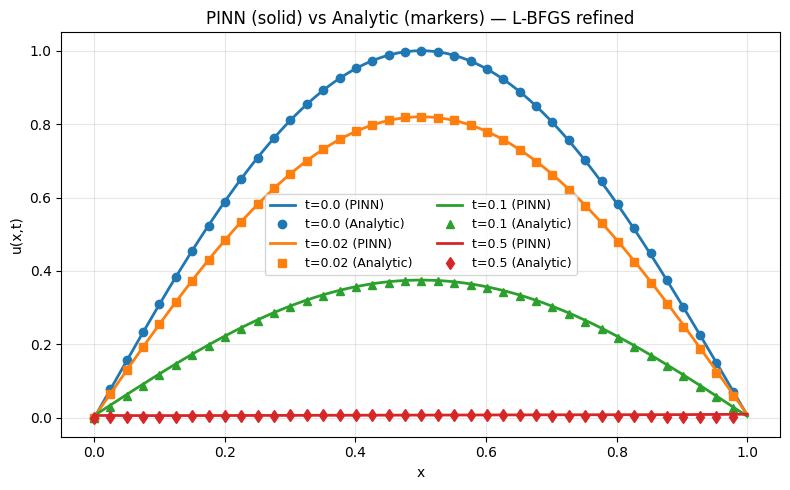

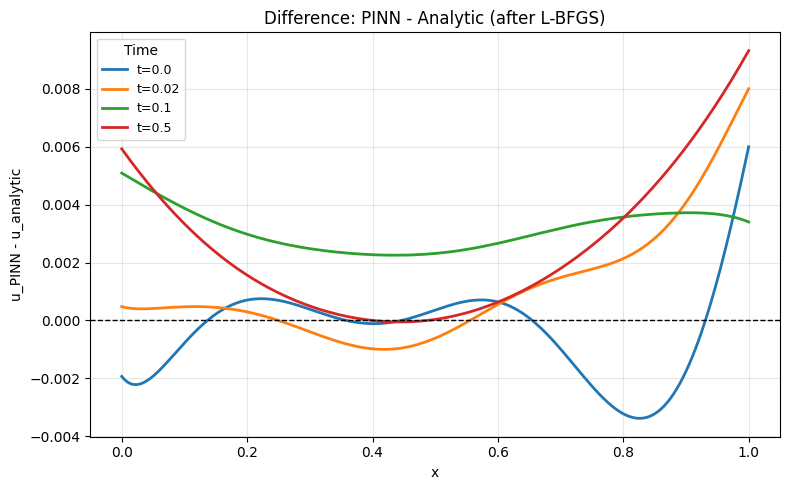


Relative L2 errors (per time) after L-BFGS:
 t =  0.0  | relative L2 error = 2.339e-03
 t = 0.02  | relative L2 error = 3.950e-03
 t =  0.1  | relative L2 error = 1.217e-02
 t =  0.5  | relative L2 error = 6.792e-01
Max absolute PDE residual on evaluation grid (t=0.02): 0.21024638

All done. If errors still large for large t, consider:
- increasing N_coll, especially biasing more to larger t
- deeper/wider network widths list (or different activations)
- more L-BFGS iterations or different initial lr for Adam


In [ ]:
"""
Annotated PINN for 1D diffusion (heat) equation with Adam + L-BFGS refinement.
Each line and important block is commented to explain purpose and gotchas.
Author: ChatGPT (annotated by request)
"""

# -------------------- imports --------------------
import numpy as np                          # numerical arrays and RNG
import tensorflow as tf                     # neural networks and autodiff
import matplotlib.pyplot as plt             # plotting
from scipy.optimize import minimize         # L-BFGS-B optimizer wrapper from scipy
import time                                 # timing utilities

# -------------------- reproducibility --------------------
np.random.seed(1234)                        # seed numpy RNG for repeatability
tf.random.set_seed(1234)                    # seed TensorFlow RNG for repeatability

# -------------------- PDE parameters --------------------
D = 1.0                                     # diffusion coefficient in u_t = D * u_xx
L = 1.0                                     # spatial domain length (x in [0, L])
T_final = 0.5                               # final time for the problem

# -------------------- analytic IC and solution --------------------
def f_init(x):
    # initial condition function u(x,0) = sin(pi * x)
    # ensure returned shape is (N,1) to match network output shape
    return np.sin(np.pi * x).reshape(-1, 1)

def analytic_solution(x, t):
    # exact analytical solution for single sine mode IC
    # u(x,t) = sin(pi x) * exp(-pi^2 t)
    # x can be array, t can be scalar or array broadcastable with x
    return np.sin(np.pi * x) * np.exp(- (np.pi**2) * t)

# -------------------- PINN model --------------------
class PINN(tf.keras.Model):
    # A simple fully-connected neural network mapping (x,t) -> u
    def __init__(self, widths=[64,64,64,64]):
        super().__init__()
        # create list of Dense hidden layers with tanh activation
        # kernel_initializer 'glorot_normal' is a common default; activation tanh helps PDEs
        self.hidden = [tf.keras.layers.Dense(w, activation=tf.nn.tanh,
                                             kernel_initializer='glorot_normal') for w in widths]
        # final output layer producing a single scalar value (no activation)
        self.out = tf.keras.layers.Dense(1, activation=None, kernel_initializer='glorot_normal')

    def call(self, xt):
        # xt: tensor with shape (batch_size, 2), columns are [x, t]
        z = xt                                 # start with input
        for layer in self.hidden:              # propagate through hidden layers
            z = layer(z)
        return self.out(z)                    # return final scalar output

# -------------------- derivatives and residual (auto-diff) --------------------
@tf.function
def pde_residual(model, xt):
    # Compute PDE residual r = u_t - D * u_xx using TensorFlow autodiff
    # Also return u and derivatives for diagnostics
    x = xt[:, 0:1]                          # column vector of x values (shape (N,1))
    t = xt[:, 1:2]                          # column vector of t values (shape (N,1))

    # Use nested GradientTapes to get second derivatives
    with tf.GradientTape(persistent=True) as tape2:
        tape2.watch([x, t])                 # ensure tape watches x and t for gradients
        with tf.GradientTape(persistent=True) as tape1:
            tape1.watch([x, t])             # inner tape to compute first derivatives
            u = model(tf.concat([x, t], axis=1))  # network prediction u(x,t)
        # first derivatives
        u_x = tape1.gradient(u, x)          # du/dx
        u_t = tape1.gradient(u, t)          # du/dt
    # second derivative
    u_xx = tape2.gradient(u_x, x)          # d^2u/dx^2
    # delete persistent tapes to free resources (important!)
    del tape1, tape2

    r = u_t - D * u_xx                     # PDE residual r(x,t)
    return r, u, u_t, u_x, u_xx           # return residual and diagnostics

# -------------------- loss wrapper --------------------
@tf.function
def loss_fn(model, x_coll_tf, t_coll_tf, x_ic_tf, t_ic_tf, u_ic_tf, x_b_tf, t_b_tf, u_b_tf):
    # Concatenate collocation x and t into xt pairs
    xt_coll = tf.concat([x_coll_tf, t_coll_tf], axis=1)
    r_coll, _, _, _, _ = pde_residual(model, xt_coll)   # PDE residuals at collocation points
    loss_pde = tf.reduce_mean(tf.square(r_coll))        # mean squared residual (PDE loss)

    # Initial condition loss: evaluate network at (x_ic, 0) and compare to u_ic
    xt_ic = tf.concat([x_ic_tf, t_ic_tf], axis=1)
    _, u_pred_ic, _, _, _ = pde_residual(model, xt_ic)  # use pde_residual for u eval convenience
    loss_ic = tf.reduce_mean(tf.square(u_pred_ic - u_ic_tf))  # MSE for IC

    # Boundary condition loss: evaluate network at boundary points x=0 and x=L with random times
    xt_b = tf.concat([x_b_tf, t_b_tf], axis=1)
    _, u_pred_b, _, _, _ = pde_residual(model, xt_b)
    loss_bc = tf.reduce_mean(tf.square(u_pred_b - u_b_tf))    # MSE for BC

    # total loss: sum of PDE loss, initial condition loss, and boundary condition loss
    return loss_pde + loss_ic + loss_bc, loss_pde, loss_ic, loss_bc

# -------------------- training data generation --------------------
# Collocation points for enforcing PDE residual
N_coll = 6000                               # number of collocation (PDE) points
x_coll = np.random.rand(N_coll, 1) * L      # x uniform in [0, L]
# bias sampling toward larger t by using exponent < 1 on uniform randoms
# sqrt (exponent 0.5) produces more samples near T_final than near 0
t_coll = T_final * (np.random.rand(N_coll, 1) ** 0.5)

# Initial condition samples (at t=0)
N_ic = 300
x_ic = np.linspace(0, L, N_ic).reshape(-1,1)  # evenly spaced x for IC
t_ic = np.zeros_like(x_ic)                    # t=0 for IC points
u_ic = f_init(x_ic)                           # initial condition u(x,0)

# Boundary condition samples: x=0 and x=L with random times in [0, T_final]
N_bc = 400
t_bc_rand = np.random.rand(N_bc, 1) * T_final
x_b0 = np.zeros((N_bc//2,1))                  # x=0 half
x_bL = L * np.ones((N_bc - N_bc//2, 1))       # x=L other half
x_b = np.vstack([x_b0, x_bL])                 # stack boundaries
# split the random times into two halves and stack (matching x positions above)
t_b = np.vstack([t_bc_rand[:N_bc//2], t_bc_rand[N_bc//2:]])
u_b = np.zeros_like(t_b)                    # u=0 at Dirichlet boundaries

# convert numpy arrays to TensorFlow tensors (float32 by default)
x_coll_tf = tf.convert_to_tensor(x_coll, dtype=tf.float32)
t_coll_tf = tf.convert_to_tensor(t_coll, dtype=tf.float32)
# IC tensors
x_ic_tf = tf.convert_to_tensor(x_ic, dtype=tf.float32)
t_ic_tf = tf.convert_to_tensor(t_ic, dtype=tf.float32)
u_ic_tf = tf.convert_to_tensor(u_ic, dtype=tf.float32)
# BC tensors
x_b_tf = tf.convert_to_tensor(x_b, dtype=tf.float32)
t_b_tf = tf.convert_to_tensor(t_b, dtype=tf.float32)
u_b_tf = tf.convert_to_tensor(u_b, dtype=tf.float32)

# -------------------- model and optimizer --------------------
model = PINN(widths=[64,64,64,64])           # instantiate the PINN with 4 hidden layers, 64 neurons each
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)  # Adam optimizer for initial training

# -------------------- Adam training --------------------
@tf.function
def train_step():
    # performs one Adam update step on the total loss
    with tf.GradientTape() as tape:
        total_loss, loss_pde, loss_ic, loss_bc = loss_fn(
            model,
            x_coll_tf, t_coll_tf,
            x_ic_tf, t_ic_tf, u_ic_tf,
            x_b_tf, t_b_tf, u_b_tf
        )
    grads = tape.gradient(total_loss, model.trainable_variables)  # compute gradients
    optimizer.apply_gradients(zip(grads, model.trainable_variables))  # apply Adam update
    return total_loss, loss_pde, loss_ic, loss_bc

print("Adam training start...")
t0 = time.time()
epochs_adam = 4000                            # number of Adam training iterations
for ep in range(1, epochs_adam+1):
    tot, lpde, lic, lbc = train_step()         # run a single training step
    # print progress every 500 epochs and on first epoch
    if ep % 500 == 0 or ep == 1:
        print(f"Epoch {ep:4d} | total={tot.numpy():.3e} pde={lpde.numpy():.3e} ic={lic.numpy():.3e} bc={lbc.numpy():.3e}")
t1 = time.time()
print(f"Adam finished in {t1-t0:.1f}s\n")

# -------------------- helper: flatten/unflatten model weights --------------------
# SciPy's minimize wants a flat 1D numpy array; we must convert back and forth

def get_weights_vector():
    """Return 1D numpy vector of all trainable variables concatenated."""
    w = []
    for var in model.trainable_variables:
        # flatten each variable to 1D and convert to numpy
        w.append(tf.reshape(var, [-1]).numpy())
    # concatenate into single vector
    return np.concatenate(w, axis=0)


def set_weights_from_vector(w_vector):
    """Assign values from 1D numpy vector to model.trainable_variables in order."""
    idx = 0
    for var in model.trainable_variables:
        shape = var.shape
        size = tf.size(var).numpy()               # number of elements in variable
        slice_ = w_vector[idx: idx + size]        # take slice for this variable
        slice_ = slice_.reshape(shape)            # reshape back to variable shape
        var.assign(slice_)                        # assign values into TF variable
        idx += size


def loss_and_grad(w_vector):
    """
    Function passed to scipy.optimize.minimize. It:
      - sets model weights from w_vector
      - computes TF loss and gradients
      - returns (loss_float, grad_vector)
    SciPy expects gradients as a 1D numpy vector and the function to return loss (float) and gradient.
    """
    # set model weights to the candidate vector
    set_weights_from_vector(w_vector)

    # compute loss and grads using TF's autodiff
    with tf.GradientTape() as tape:
        total_loss, loss_pde, loss_ic, loss_bc = loss_fn(
            model,
            x_coll_tf, t_coll_tf,
            x_ic_tf, t_ic_tf, u_ic_tf,
            x_b_tf, t_b_tf, u_b_tf
        )
    grads = tape.gradient(total_loss, model.trainable_variables)  # list of gradient tensors

    # flatten gradients into a single numpy vector (float64 for SciPy)
    grad_vector = np.concatenate([tf.reshape(g, [-1]).numpy() for g in grads], axis=0).astype(np.float64)
    return float(total_loss.numpy()), grad_vector

# -------------------- L-BFGS refinement --------------------
print("Starting L-BFGS refinement (this may take a bit)...")
w0 = get_weights_vector().astype(np.float64)   # initial vector for L-BFGS (from Adam-trained model)

# callback to monitor progress (optional)
history = {'loss':[]}
def callbackF(xk):
    # called at each iteration of L-BFGS with current parameter vector xk
    loss_val, _ = loss_and_grad(xk)              # compute loss again for logging (costly)
    history['loss'].append(loss_val)
    print(f"L-BFGS iter loss: {loss_val:.6e}")

# run L-BFGS-B (jac supplied) using SciPy minimize
# method 'L-BFGS-B' uses limited-memory BFGS; jac=True means we return gradient in loss_and_grad
# options: maxiter controls iterations; ftol sets tolerance for convergence
t2 = time.time()
res = minimize(fun=lambda w: loss_and_grad(w),
               x0=w0,
               jac=True,
               method='L-BFGS-B',
               callback=callbackF,
               options={'maxiter': 500, 'ftol':1e-9})
t3 = time.time()
print(f"L-BFGS finished in {t3-t2:.1f}s, success={res.success}, message: {res.message}")
# assign final weights back to model
set_weights_from_vector(res.x)

# -------------------- evaluation and plotting --------------------
# create a dense spatial grid for plotting
x_plot = np.linspace(0, L, 400)
# times to evaluate and plot
t_plot = [0.0, 0.02, 0.1, 0.5]
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
markers = ['o','s','^','d']

# plot PINN (solid) vs analytic (thinned markers)
plt.figure(figsize=(8,5))
for i, tval in enumerate(t_plot):
    X = x_plot.reshape(-1,1)                    # x_column for model input
    T = (tval * np.ones_like(X)).reshape(-1,1)  # corresponding t column
    XT = tf.convert_to_tensor(np.hstack([X, T]), dtype=tf.float32)  # (N,2) tensor
    u_pred = model(XT).numpy().reshape(-1)      # model predictions flattened
    u_true = analytic_solution(x_plot, tval).reshape(-1)  # analytic values
    plt.plot(x_plot, u_pred, color=colors[i], linewidth=2, label=f"t={tval} (PINN)")
    # plot only every 10th analytic point as marker to avoid clutter
    plt.plot(x_plot[::10], u_true[::10], linestyle='None', marker=markers[i], color=colors[i],
             markersize=6, label=f"t={tval} (Analytic)")

plt.xlabel("x"); plt.ylabel("u(x,t)")
plt.title("PINN (solid) vs Analytic (markers) — L-BFGS refined")
plt.legend(ncol=2, fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# difference plots and relative L2 errors
plt.figure(figsize=(8,5))
rel_l2s = []
for i, tval in enumerate(t_plot):
    X = x_plot.reshape(-1,1)
    T = (tval * np.ones_like(X)).reshape(-1,1)
    XT = tf.convert_to_tensor(np.hstack([X, T]), dtype=tf.float32)
    u_pred = model(XT).numpy().reshape(-1)
    u_true = analytic_solution(x_plot, tval).reshape(-1)
    diff = u_pred - u_true                       # pointwise difference
    plt.plot(x_plot, diff, color=colors[i], linewidth=2, label=f"t={tval}")
    # relative L2 error: ||diff||_2 / ||u_true||_2
    rel_l2 = np.linalg.norm(diff,2) / (np.linalg.norm(u_true,2) + 1e-16)
    rel_l2s.append(rel_l2)

plt.axhline(0.0, color='k', linestyle='--', linewidth=1)
plt.xlabel("x"); plt.ylabel("u_PINN - u_analytic")
plt.title("Difference: PINN - Analytic (after L-BFGS)")
plt.legend(title="Time", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# print relative L2 errors for each time in t_plot
print("\nRelative L2 errors (per time) after L-BFGS:")
for tval, e in zip(t_plot, rel_l2s):
    print(f" t = {tval:>4}  | relative L2 error = {e:.3e}")

# compute max PDE residual on evaluation grid at t_eval = 0.02 as quick diagnostic
t_eval = 0.02
XT_eval = tf.convert_to_tensor(np.hstack([x_plot.reshape(-1,1), t_eval*np.ones((len(x_plot),1))]), dtype=tf.float32)
r_eval, u_eval, u_t_eval, u_x_eval, u_xx_eval = pde_residual(model, XT_eval)
res_np = r_eval.numpy().reshape(-1)
print("Max absolute PDE residual on evaluation grid (t=0.02):", np.max(np.abs(res_np)))

# Done
print("\nAll done. If errors still large for large t, consider:")
print("- increasing N_coll, especially biasing more to larger t")
print("- deeper/wider network widths list (or different activations)")
print("- more L-BFGS iterations or different initial lr for Adam")
